### Build A Basic Chatbot With Langgraph(GRAPH API)

In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [24]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [12]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-120b")

In [7]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [8]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph=graph_builder.compile()

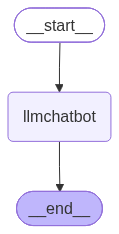

In [9]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [13]:
response=graph.invoke({"messages":"Hello!"})

In [ ]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [18]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I'm doing great, thanks for asking. How can I assist you today?


### Chatbot with Tools

In [25]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("Who is Nimesh Akarshana?")

{'query': 'Who is Nimesh Akarshana?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://lk.linkedin.com/in/nimeshakarshana',
   'title': 'Nimesh Akarshana - Ex-Cambio AI Engineer Intern',
   'content': '# Nimesh Akarshana [...] Description: Passionate Computer Engineering undergraduate at University of Ruhuna with specialized expertise in AI/ML, computer vision, and full-stack development. CMJD-certified developer with hands-on experience building end-to-end systems including enterprise log classification, sentiment analysis applications, and sports analytics solutions. I combine technical proficiency in Python, Machine Learning frameworks (scikit-learn, BERT, YOLOv5), and web technologies (FastAPI, React) with a [...] ## Awards\n- Most Valuable Basketball Player – 2017, Rahula College (2017)',
   'score': 0.6238588,
   'raw_content': None,
   'id': '7779ab-00'},
  {'url': 'https://en.wikipedia.org/wiki/Nimesh_Patel',
   'title': 'Nimesh Patel 

In [26]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [27]:
tools=[tool,multiply]

In [28]:
llm_with_tool=llm.bind_tools(tools)

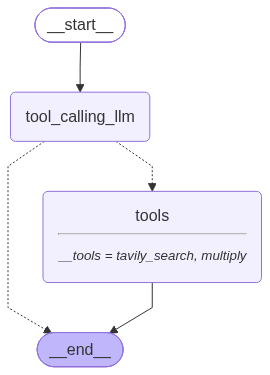

In [29]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [30]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [35]:
response['messages']

[HumanMessage(content='What is the recent ai news', additional_kwargs={}, response_metadata={}, id='c0435b9d-4123-4653-9602-a7e80ed843fd'),
 AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is the recent ai news". Likely they want a summary of recent AI news. We need up-to-date info, so we should search. Use tavily_search with query "recent AI news November 2026" maybe. Let\'s search.', 'tool_calls': [{'id': 'fc_85598d54-bb25-4e84-9f88-557a84c448f2', 'function': {'arguments': '{"query":"AI news November 2026","search_depth":"advanced","time_range":"day"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 106, 'prompt_tokens': 348, 'total_tokens': 454, 'completion_time': 0.223593592, 'completion_tokens_details': {'reasoning_tokens': 56}, 'prompt_time': 0.061899391, 'prompt_tokens_details': None, 'queue_time': 0.395990271, 'total_time': 0.285492983}, 'model_name': 'openai/gpt-oss-120b', 'system_fin

In [37]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_85598d54-bb25-4e84-9f88-557a84c448f2)
 Call ID: fc_85598d54-bb25-4e84-9f88-557a84c448f2
  Args:
    query: AI news November 2026
    search_depth: advanced
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=clNuFLKQlh0", "title": "10+ Biggest AI Updates You Cannot Afford to Miss This Week!", "content": "# 10+ Biggest AI Updates You Cannot Afford to Miss This Week!\n## Channel: Mayank Aggarwal\n74.3K subscribers\n34 likes\n\n### Description\n532 views\nPosted: 2026-11-02\nThe AI world is changing faster than anyone expected, and some of the biggest develo

In [39]:
response=graph.invoke({"messages":"What is 521 multiplied by 212312"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 521 multiplied by 212312
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_c253ed0f-c028-4f2d-a53e-dab7c4cf48fd)
 Call ID: fc_c253ed0f-c028-4f2d-a53e-dab7c4cf48fd
  Args:
    a: 521
    b: 212312
================================= Tool Message =================================
Name: multiply

110614552


In [40]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_efbfec89-ff1b-4b3b-a6cd-9c5b447262f2)
 Call ID: fc_efbfec89-ff1b-4b3b-a6cd-9c5b447262f2
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=clNuFLKQlh0", "title": "10+ Biggest AI Updates You Cannot Afford to Miss This Week!", "content": "# 10+ Biggest AI Updates You Cannot Afford to Miss This Week!\n## Channel: Mayank Aggarwal\n74.3K subscribers\n34 likes\n\n### Description\n532 views\nPosted: 2026-11-02\nThe AI world is changing faster than anyone

### ReAct Agent Architecure

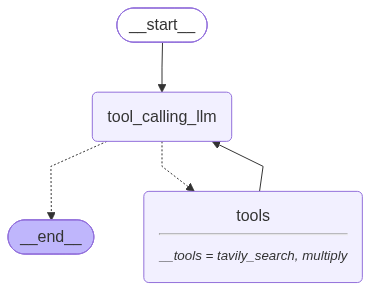

In [41]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [42]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_a6b50218-6897-4904-bb66-67071ce603e1)
 Call ID: fc_a6b50218-6897-4904-bb66-67071ce603e1
  Args:
    query: AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://llm-stats.com/llm-updates", "title": "AI Updates Today (November 2026) – Latest AI Model Releases", "content": "1.0M\n\nPopular Models\n\nDeepSeek-V4.1-Flash$30.00/M\n\nDeepSeek-V4.1-Flash$30.00/M### Higgsfield\n\n45 active models·higgsfield.ai\n\nInput price\n\n—\n\nMax tokens\n\n4K### xAI\n\n44 active models·docs.x.ai\n\nInput price\n\nMax token